import libraries

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix



Load dataset-STEP-1

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/ML_AL/heart_disease.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


EDA

In [ ]:
#tail
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


In [ ]:
#shape
df.shape

(1025, 14)

In [ ]:
#datatypes
df.dtypes

,0
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


In [ ]:
#info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
#describe
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


STEP-2

In [ ]:
#detect missing values
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
#categorical values
cat_cols=df.select_dtypes(include='object').columns


In [ ]:
#numerical values
num_cols=df.select_dtypes(include='number').columns

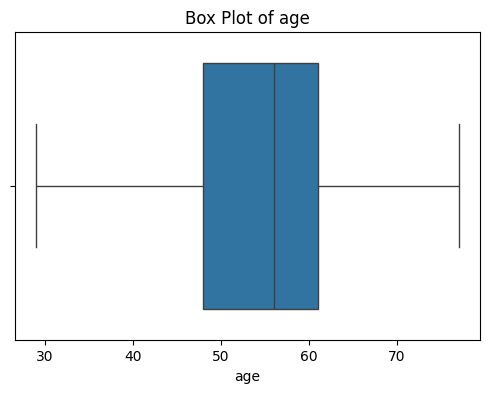

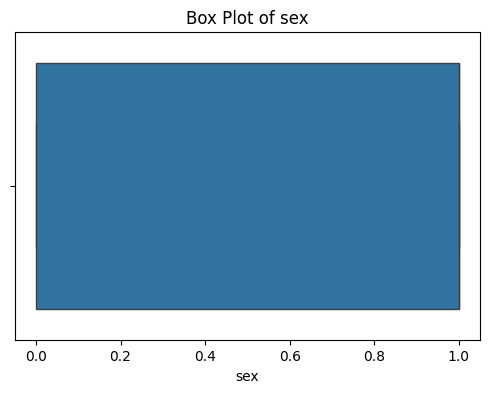

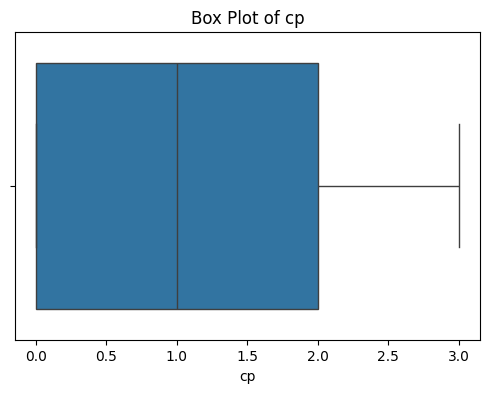

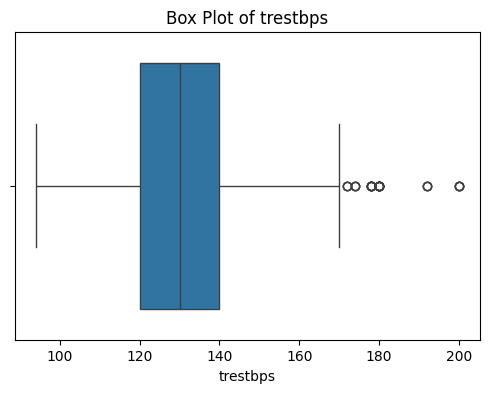

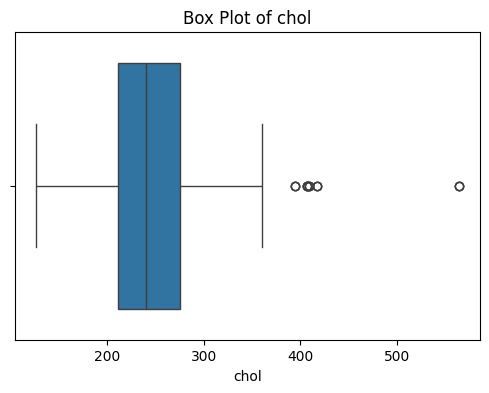

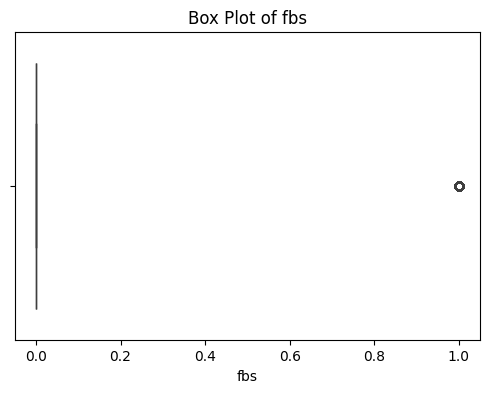

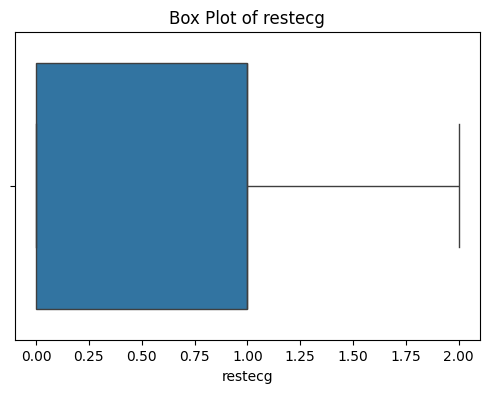

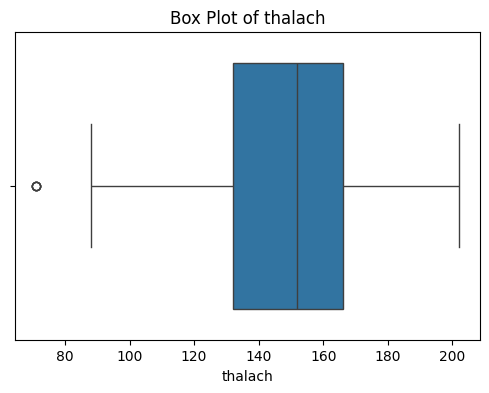

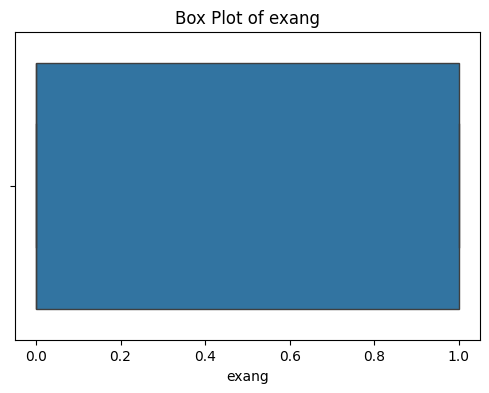

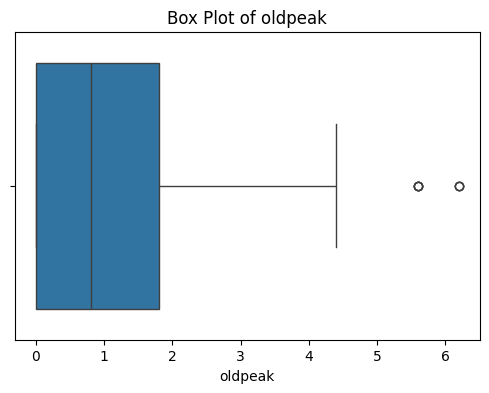

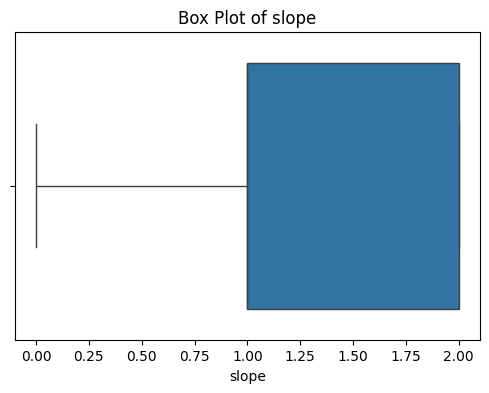

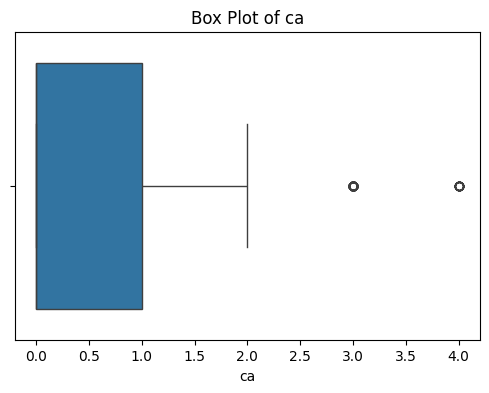

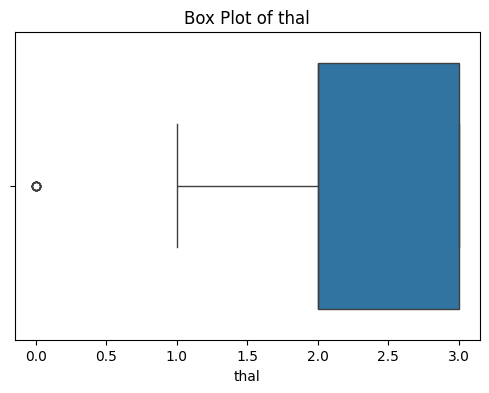

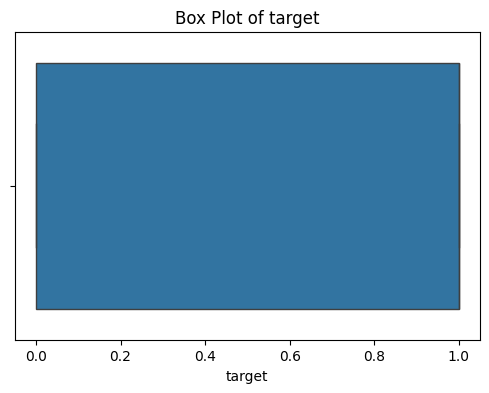

In [ ]:
#finding outliers in numerical columns
for col in num_cols:
    plt.figure(figsize=(6, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Box Plot of {col}")
    plt.show()

In [ ]:
#distribution of categorical values
print(cat_cols)

Index([], dtype='object')


In [ ]:
#display category count
for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts())

In [ ]:
#visualization of distribution
for col in cat_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=df[col])

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()

No need to handle missing values because the data is alread clean and every column is filled no missing  values

In [ ]:
#handle outliers

for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

print("Outliers handled successfully")
print(df.shape)

Outliers handled successfully
(769, 14)


In [ ]:
#encoding
#onehot encoding for chest pain type, resting electrocardiographic results, thal
cat_cols=['cp', 'restecg', 'thal']
df = pd.get_dummies(
    df,
    columns=cat_cols,
    dtype=int
)

print(df.head())

   age  sex  trestbps  chol  fbs  thalach  exang  oldpeak  slope  ca  ...  \
0   52    1       125   212    0      168      0      1.0      2   2  ...   
2   70    1       145   174    0      125      1      2.6      0   0  ...   
3   61    1       148   203    0      161      0      0.0      2   1  ...   
5   58    0       100   248    0      122      0      1.0      1   0  ...   
7   55    1       160   289    0      145      1      0.8      1   1  ...   

   cp_0  cp_1  cp_2  cp_3  restecg_0  restecg_1  restecg_2  thal_1  thal_2  \
0     1     0     0     0          0          1          0       0       0   
2     1     0     0     0          0          1          0       0       0   
3     1     0     0     0          0          1          0       0       0   
5     1     0     0     0          1          0          0       0       1   
7     1     0     0     0          1          0          0       0       0   

   thal_3  
0       1  
2       1  
3       1  
5       0  
7       

No need for binary encoding for sex and fasting blood sugar.They are already in binary variable

In [ ]:
#Scaling resting blood pressure, serum cholesterol, maximum heart rate, and oldpeak using StandardScaler
scaler = StandardScaler()
columns_to_scale = ['trestbps', 'chol', 'thalach', 'oldpeak']
df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])
print(df[columns_to_scale].head())

   trestbps      chol   thalach   oldpeak
0 -0.240805 -0.675971  0.768418  0.026266
2  1.066034 -1.530053 -1.138183  1.550693
3  1.262060 -0.878254  0.458041 -0.926501
5 -1.874354  0.133160 -1.271202  0.026266
7  2.046163  1.054670 -0.251392 -0.164287


Train-test-split-STEP-3

In [ ]:
#train-test-split
# Separate features and target
X = df.drop('target', axis=1)
y = df['target']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (615, 20)
X_test shape: (154, 20)
y_train shape: (615,)
y_test shape: (154,)


In [ ]:
#splitting for regression
# Features and target
X_reg = df.drop('chol', axis=1)
y_reg = df['chol']

# Train-test split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Regression:")
print("X_train:", X_train_reg.shape)
print("X_test:", X_test_reg.shape)
print("y_train:", y_train_reg.shape)
print("y_test:", y_test_reg.shape)

Regression:
X_train: (615, 20)
X_test: (154, 20)
y_train: (615,)
y_test: (154,)


In [ ]:
#splitting for classification
# Features and target
X_clf = df.drop('target', axis=1)
y_clf = df['target']

# Train-test split
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf,
    y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

print("\nClassification:")
print("X_train:", X_train_clf.shape)
print("X_test:", X_test_clf.shape)
print("y_train:", y_train_clf.shape)
print("y_test:", y_test_clf.shape)


Classification:
X_train: (615, 20)
X_test: (154, 20)
y_train: (615,)
y_test: (154,)


MODEL BUILDING Regression Task-STEP-4

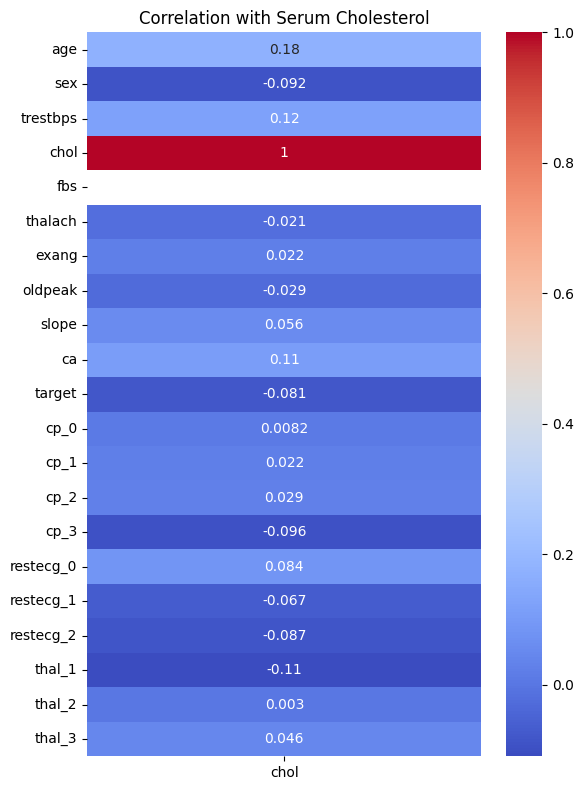

In [ ]:
#correlation
chol_corr = df.select_dtypes(include='number').corr()[["chol"]]

plt.figure(figsize=(6, 8))

sns.heatmap(
    chol_corr,
    cmap="coolwarm",
    annot=True
)

plt.title("Correlation with Serum Cholesterol")

plt.tight_layout()
plt.show()

In [ ]:
# Correlation with target
corr = df.corr(numeric_only=True)['chol'].abs()

# Select features with correlation >= 0.10
selected_features = corr[corr >= 0.10].index.tolist()

# Remove target itself
selected_features.remove('chol')

print("Selected features:", selected_features)

Selected features: ['age', 'trestbps', 'ca', 'thal_1']


In [ ]:
X = df[selected_features]
y = df['chol']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:
X.head()

,age,trestbps,ca,thal_1
0,52,-0.240805,2,0
2,70,1.066034,0,0
3,61,1.262060,1,0
5,58,-1.874354,0,0
7,55,2.046163,1,0


In [ ]:
#prediction
new_data = [[52	,-0.240805,	2,	0]]

new_data_scaled = scaler.transform(new_data)

result = lr_model.predict(new_data_scaled)

print("Prediction:", result)

Prediction: [0.09733164]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
y_pred_train = lr_model.predict(X_train)
y_pred_test = lr_model.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [106]:
#SVM
svm_model = SVR()




In [107]:
svm_model.fit(X_train_scaled, y_train)

SVR()

In [109]:
new_data = [[52, -0.240805, 2, 0]]

new_data_scaled = scaler.transform(new_data)

result = svm_model.predict(new_data_scaled)

print("Prediction:", result)

Prediction: [0.81871746]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [108]:
#prediction
y_pred_svm = svm_model.predict(X_test_scaled)

print("Predictions:", y_pred_svm)

Predictions: [-0.8991614  -0.12985993 -0.77959121 -0.26136427 -0.08430084 -0.79965626
 -0.77838086 -0.27192361  0.14044639  0.18763778 -0.08097345  0.16963315
  0.03114132  0.18669686  0.79696042  0.03716913  0.13317432 -0.19176476
 -0.0735659  -0.48834413 -0.23367936 -0.22128428 -0.95529567 -0.41488782
 -0.8120406   0.12667441  0.03114132  0.512957    0.12213864 -0.05018613
  0.93232638  0.03335346  0.49575713 -0.34879874  0.05391704 -0.23367936
 -0.12985993 -0.1313494   0.03114132 -0.48834413 -0.21884591 -0.03720976
  0.41401421  0.02187537 -0.09863374  0.25750051  0.23660836  0.32406051
  0.93232638 -0.01319971  0.13037519 -0.52172889 -0.22184112  0.12667441
  0.96577346 -0.17769992 -0.03720976 -0.755379   -0.01319971 -0.42998543
 -0.42998543  0.19568315 -0.45293218  0.11647878 -0.08430084  0.96577346
 -0.23367936  0.16817607  0.01549901 -0.34879874 -0.07835956 -0.22636758
 -0.92829738  0.19964237 -0.00174925 -0.43238705 -0.59996926  0.43083871
 -0.59837694 -0.27840563  0.19922761  

In [113]:
#random forest
rf_model = RandomForestRegressor(n_estimators=100,random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [114]:
new_data = [[52, -0.240805, 2, 0]]

result = rf_model.predict(new_data)

print("Prediction:", result)

Prediction: [-0.64450467]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [115]:
y_pred_rf = rf_model.predict(X_test)

print("Predictions:", y_pred_rf)

Predictions: [ 2.15084441e-01  9.23186280e-01 -1.30439579e+00 -2.53161844e-01
 -1.82288690e-01 -9.50086401e-01 -8.02734690e-01  6.64264420e-01
  3.42034837e-01  7.46975570e-01 -6.62035833e-01  1.34973988e+00
 -2.88401219e-01 -9.75022696e-02  8.63400503e-01  9.33773253e-02
  4.66027372e-01 -1.65861528e+00  5.04375463e-01 -4.82678503e-01
  1.82847736e+00 -1.88480788e-01 -8.44315023e-01 -6.05396676e-01
  7.67878116e-01 -4.62000716e-01 -2.88401219e-01  7.91412834e-01
  4.57660735e-01 -3.80188600e-01  1.36154102e+00  2.51017240e-02
  3.24654239e-01 -7.38328633e-01  8.61431322e-02  1.82847736e+00
  9.23186280e-01 -1.27335222e-01 -2.88401219e-01 -4.82678503e-01
  1.18325882e-01 -1.38321502e-02  2.30275431e+00 -2.75900629e-01
  1.21499308e-01  3.03999833e-01 -3.02417623e-01  8.54859678e-01
  1.36154102e+00  1.68287021e+00  1.27091466e-01  2.02610341e-01
 -7.13955060e-01 -4.62000716e-01  1.00387460e+00  3.09850142e-01
 -1.38321502e-02  2.98941860e-01  1.68287021e+00  3.15930574e-01
  3.15930574

Classification task

In [119]:
# Classification target
X = df.drop('target', axis=1)
y = df['target']

In [120]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [121]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [122]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [123]:
#prediction
y_pred_log = log_model.predict(X_test_scaled)

print("Predictions:", y_pred_log)

Predictions: [1 0 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 0 0 0 1 1 1 1 0 0 0 1 1 1 0 1 1 1 1 1 0
 1 0 0 1 1 1 1 0 1 1 0 0 1 0 1 0 0 0 1 1 1 1 1 1 0 1 0 1 0 1 0 1 1 0 0 1 1
 0 1 1 0 1 1 1 0 1 0 1 0 1 1 0 1 0 1 0 0 0 1 1 1 1 0 1 1 1 1 1 0 1 0 0 1 1
 1 1 1 0 0 1 0 1 1 1 0 0 1 1 1 1 1 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 1 0 0 1 1
 1 1 1 0 1 1]


In [125]:
#KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [126]:
#prediction
y_pred_knn = knn_model.predict(X_test_scaled)

print("Predictions:", y_pred_knn)

Predictions: [1 0 1 1 0 1 1 0 1 1 1 1 0 0 0 1 1 0 0 0 1 1 1 1 0 0 0 0 1 1 0 1 0 1 1 1 0
 1 0 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0 1 1 0 1 1 1 1 0 1 1 0 1 1 0 1 0 0 0 0 1
 0 0 1 1 1 1 1 0 1 0 1 0 1 1 0 1 0 1 0 0 1 0 1 0 1 0 1 1 1 1 0 0 1 1 0 1 1
 0 1 1 0 0 1 0 1 1 0 0 0 1 1 1 1 1 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 1 0 0 1 1
 1 0 1 0 1 1]


In [129]:
#random forest
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [130]:
#prediction
y_pred_rf = rf_model.predict(X_test)

print("Predictions:", y_pred_rf)

Predictions: [1 0 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 1 1 0 1 1 1 1 1 0
 1 0 0 1 1 1 0 0 1 1 0 0 0 0 0 0 0 1 1 1 1 0 1 1 0 1 0 1 1 1 0 1 1 0 0 1 1
 0 0 1 1 1 1 1 0 0 0 1 0 1 1 0 1 0 1 1 1 0 1 1 1 1 0 0 1 1 1 1 0 1 0 0 1 1
 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 0 1 1 1 0 0 1 0 1 0 0 1 1 0 0 1 1
 1 0 1 0 0 1]


In [132]:
#evaluation on linear regression
model = LinearRegression()

model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_test)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 0.2754532863257491
MSE: 0.12231168932941673
RMSE: 0.3497308812921969
R² Score: 0.49639860692075566


In [149]:
#evaluation on svm
model = SVR()

model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)

y_pred_test = model.predict(X_test)

mae_svm = mean_absolute_error(y_test, y_pred_test)

mse_svm = mean_squared_error(y_test, y_pred_test)

rmse_svm = np.sqrt(mse_svm)

r2_svm = r2_score(y_test, y_pred_test)

print("SVM Regression")
print("MAE:", mae_svm)

print("MSE:", mse_svm)

print("RMSE:", rmse_svm)

print("R² Score:", r2_svm)

SVM Regression
MAE: 0.3273362370063144
MSE: 0.15312352567561524
RMSE: 0.39131001223533146
R² Score: 0.369535150186998


In [150]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)

y_pred_test = model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_test)

mse_rf = mean_squared_error(y_test, y_pred_test)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, y_pred_test)

print("Random Forest Regression")
print("MAE:", mae_rf)

print("MSE:", mse_rf)

print("RMSE:", rmse_rf)

print("R² Score:", r2_rf)

Random Forest Regression
MAE: 0.04493506493506493
MSE: 0.005700000000000001
RMSE: 0.07549834435270751
R² Score: 0.9765310416666667


In [141]:
#evaluation on classification models
#logistic regression
print("Logistic Regression")

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1-Score:", f1_score(y_test, y_pred_log))

Logistic Regression
Accuracy: 0.8701298701298701
Precision: 0.8645833333333334
Recall: 0.9222222222222223
F1-Score: 0.8924731182795699
Confusion Matrix:
[[51 13]
 [ 7 83]]


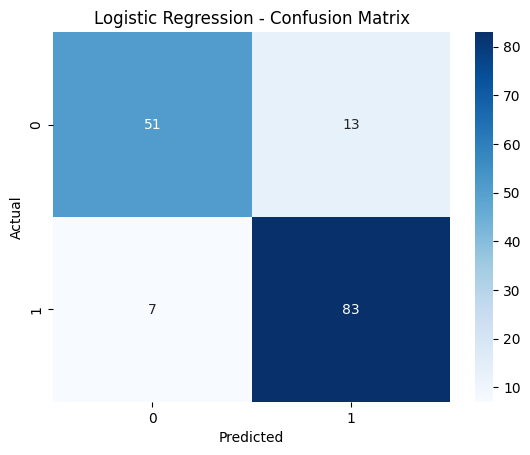

In [142]:
cm = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [145]:
#KNN
print("KNN")

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("F1-Score:", f1_score(y_test, y_pred_knn))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN
Accuracy: 0.8311688311688312
Precision: 0.8809523809523809
Recall: 0.8222222222222222
F1-Score: 0.8505747126436781
Confusion Matrix:
[[54 10]
 [16 74]]


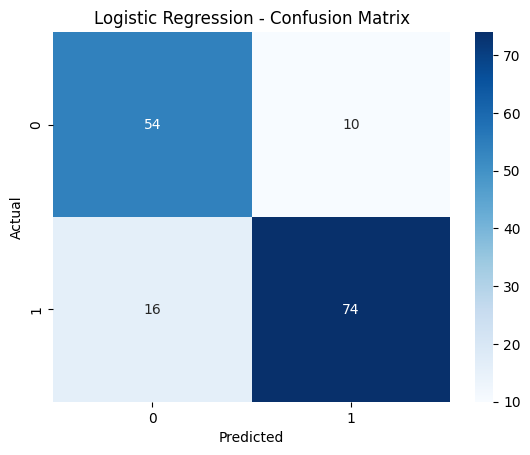

In [146]:
cm = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [147]:
print("Random Forest")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0
Confusion Matrix:
[[64  0]
 [ 0 90]]


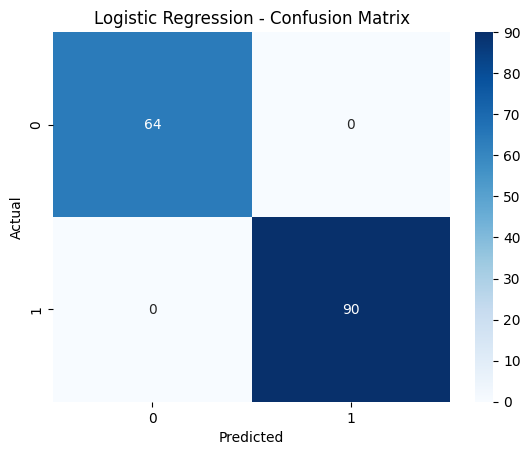

In [148]:
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Classification result
The classification models were evaluated using Accuracy, Precision, Recall, and F1-Score. Since Recall was selected as the key performance metric, the model with the highest Recall value was considered the best-performing classification model. The performance of Logistic Regression, KNN, SVM, and Random Forest was compared based on these metrics.

Best Classification Model: The model with the highest Recall score is said to be more accurate that is random forest

# Regression Result
The regression models were evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), and R² Score. The models used were Linear Regression, SVM Regression, and Random Forest Regression. A higher R² Score and lower MAE and MSE indicate better regression performance.

Best Regression Model: The model with the highest R² Score is said to be more accurate which is also random forest